In [79]:
# Step 2: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [80]:
# Step 3: Create and Load Student Performance Dataset

import pandas as pd
import numpy as np

# Generate sample student data
np.random.seed(42)

n = 200

data = {
    'Study_Hours': np.random.randint(1, 10, n),
    'Attendance': np.random.randint(50, 101, n),
    'Previous_Marks': np.random.randint(30, 101, n),
    'Assignment_Score': np.random.randint(30, 101, n)
}

df = pd.DataFrame(data)

# Generate final marks using sample features
df['Final_Marks'] = (
    df['Study_Hours'] * 3 +
    df['Attendance'] * 0.2 +
    df['Previous_Marks'] * 0.3 +
    df['Assignment_Score'] * 0.2 +
    np.random.normal(0, 5, n)
).clip(0, 100).round(1)

# Create Pass/Fail target
df['Result'] = (df['Final_Marks'] >= 40).astype(int)

# Display dataset
print("Student Performance Dataset Loaded Successfully!")
print(df.head(10))

# Check dataset size
print("\nDataset Shape:", df.shape)

Student Performance Dataset Loaded Successfully!
   Study_Hours  Attendance  Previous_Marks  Assignment_Score  Final_Marks  \
0            7          50              87                37         73.5   
1            4          60              84                87         66.2   
2            8          77              91                89         87.3   
3            5          74              52                79         65.4   
4            7          99              38                57         54.9   
5            3          72              41                70         62.8   
6            7          80              30                93         62.4   
7            8          79              87                56         79.6   
8            5          91              30                92         63.8   
9            4          84              63                46         52.8   

   Result  
0       1  
1       1  
2       1  
3       1  
4       1  
5       1  
6       1  
7      

In [81]:
# Step 4: Data Preprocessing

# Recreate Result column with a balanced Pass/Fail target
df['Result'] = (df['Final_Marks'] >= 65).astype(int)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Check dataset information
print("\nDataset Information:")
print(df.info())

# Check Pass and Fail counts
print("\nPass/Fail Distribution:")
print(df['Result'].value_counts())

# Display updated dataset
print("\nUpdated Dataset:")
print(df.head())

Missing Values:
Study_Hours         0
Attendance          0
Previous_Marks      0
Assignment_Score    0
Final_Marks         0
Result              0
dtype: int64

Duplicate Rows: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Study_Hours       200 non-null    int64  
 1   Attendance        200 non-null    int64  
 2   Previous_Marks    200 non-null    int64  
 3   Assignment_Score  200 non-null    int64  
 4   Final_Marks       200 non-null    float64
 5   Result            200 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 9.5 KB
None

Pass/Fail Distribution:
Result
0    104
1     96
Name: count, dtype: int64

Updated Dataset:
   Study_Hours  Attendance  Previous_Marks  Assignment_Score  Final_Marks  \
0            7          50              87                37         73.5   
1            4 

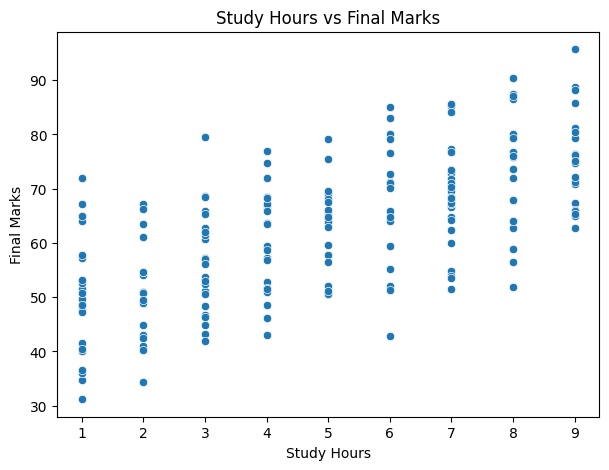

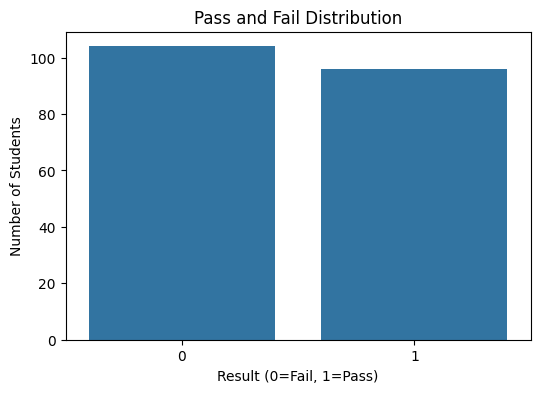

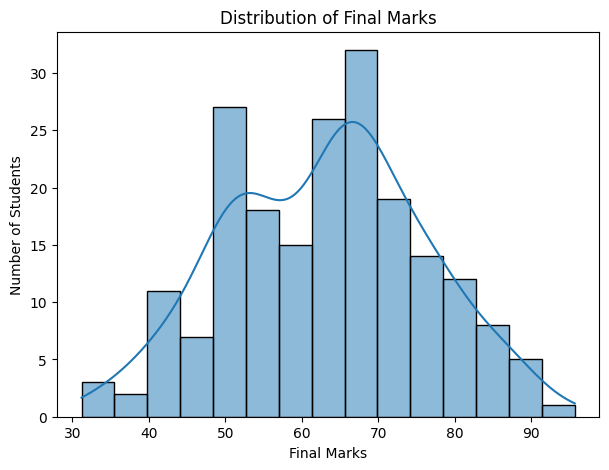

In [82]:
# Step 5: Data Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Graph 1: Study Hours vs Final Marks
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='Study_Hours', y='Final_Marks')
plt.title('Study Hours vs Final Marks')
plt.xlabel('Study Hours')
plt.ylabel('Final Marks')
plt.show()

# Graph 2: Pass and Fail Distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Result')
plt.title('Pass and Fail Distribution')
plt.xlabel('Result (0=Fail, 1=Pass)')
plt.ylabel('Number of Students')
plt.show()

# Graph 3: Final Marks Distribution
plt.figure(figsize=(7,5))
sns.histplot(data=df, x='Final_Marks', bins=15, kde=True)
plt.title('Distribution of Final Marks')
plt.xlabel('Final Marks')
plt.ylabel('Number of Students')
plt.show()

In [83]:
print(df['Result'].value_counts())

Result
0    104
1     96
Name: count, dtype: int64


In [84]:
# Step 6: Split Dataset into Training and Testing Data

from sklearn.model_selection import train_test_split

# Select input features
X = df[['Study_Hours', 'Attendance',
        'Previous_Marks', 'Assignment_Score']]

# Select target variable
y = df['Result']

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training and Testing Split Completed!")

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training and Testing Split Completed!
Training Data: (160, 4)
Testing Data: (40, 4)
Training Labels: (160,)
Testing Labels: (40,)


In [85]:
# Step 7: Train Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Create the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train all models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "Model Trained Successfully!")

print("\nAll Machine Learning Models Trained Successfully!")

Logistic Regression Model Trained Successfully!
Decision Tree Model Trained Successfully!
Random Forest Model Trained Successfully!

All Machine Learning Models Trained Successfully!


In [86]:
# Step 8: Model Testing and Accuracy Comparison

from sklearn.metrics import accuracy_score

# Create an empty dictionary
results = {}

# Test all trained models
for name, model in models.items():

    # Predict results using testing data
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Store accuracy
    results[name] = accuracy

    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

# Display comparison
print("\nModel Accuracy Comparison")

for name, accuracy in results.items():
    print(name, ":", round(accuracy * 100, 2), "%")

# Find the best model
best_model_name = max(results, key=results.get)

print("\nBest Performing Model:", best_model_name)

Logistic Regression Accuracy: 87.5 %
Decision Tree Accuracy: 80.0 %
Random Forest Accuracy: 82.5 %

Model Accuracy Comparison
Logistic Regression : 87.5 %
Decision Tree : 80.0 %
Random Forest : 82.5 %

Best Performing Model: Logistic Regression


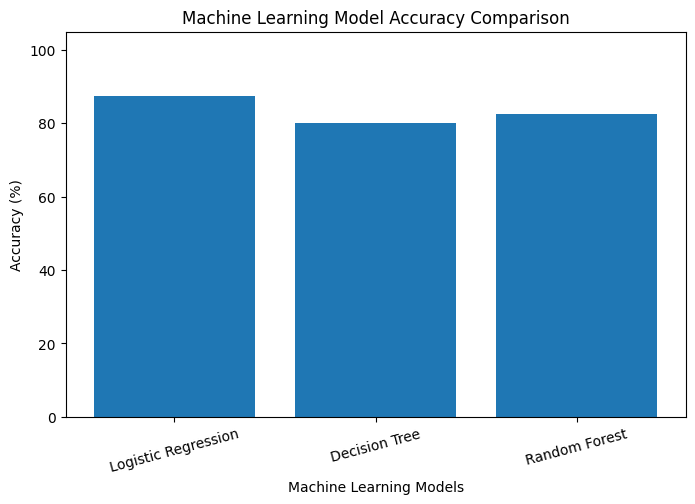

In [87]:
# Model Accuracy Comparison Graph

plt.figure(figsize=(8,5))

plt.bar(results.keys(),
        [value * 100 for value in results.values()])

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.show()

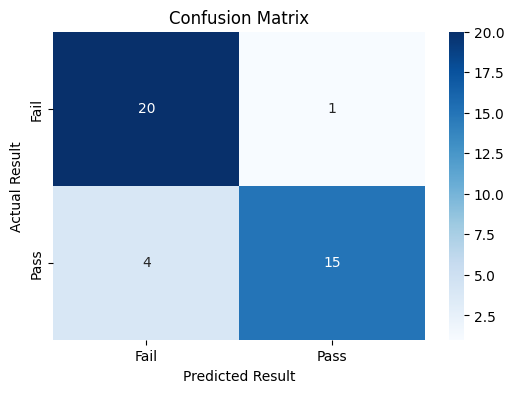

In [88]:
# Step 9: Confusion Matrix

from sklearn.metrics import confusion_matrix

# Use the best performing model
best_model = models[best_model_name]

# Predict testing data
y_pred = best_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Result')
plt.ylabel('Actual Result')

plt.show()

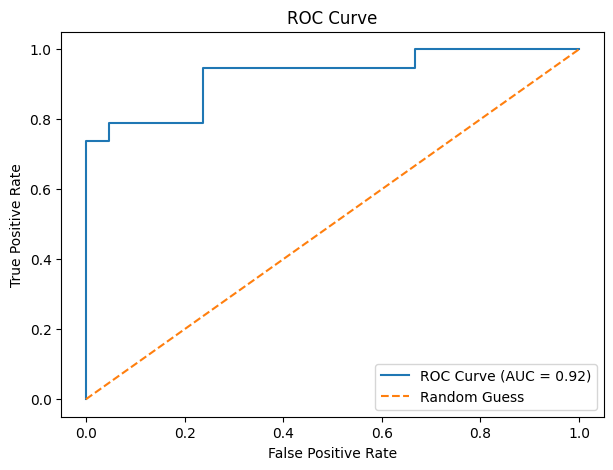

AUC Score: 0.92


In [89]:
# ROC Curve

from sklearn.metrics import roc_curve, auc

# Get prediction probabilities
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(7,5))

plt.plot(
    fpr, tpr,
    label=f'ROC Curve (AUC = {roc_auc:.2f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve')
plt.legend()
plt.show()

print("AUC Score:", round(roc_auc, 2))

In [90]:
# Step 10: Predict New Student Performance

# Enter new student details
new_student = pd.DataFrame({
    'Study_Hours': [6],
    'Attendance': [85],
    'Previous_Marks': [75],
    'Assignment_Score': [80]
})

# Predict using the best model
prediction = best_model.predict(new_student)

# Display student details
print("New Student Details:")
print(new_student)

# Display prediction
if prediction[0] == 1:
    print("\nPredicted Result: PASS")
else:
    print("\nPredicted Result: FAIL")

print("\nPrediction Model:", best_model_name)

New Student Details:
   Study_Hours  Attendance  Previous_Marks  Assignment_Score
0            6          85              75                80

Predicted Result: PASS

Prediction Model: Logistic Regression


In [91]:
'Study_Hours': [1],
'Attendance': [50],
'Previous_Marks': [30],
'Assignment_Score': [35]

SyntaxError: illegal target for annotation (1628346239.py, line 1)